In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
df = pd.read_csv("data/workloads.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (10000, 7)


,process_id,arrival_time,instructions,memory_mb,io_operations,priority,burst_time
0,P1,0,339360,155,115,10,8.72
1,P2,0,218931,2956,173,8,13.11
2,P3,0,520818,888,430,3,19.29
3,P4,0,663264,2917,51,10,21.57
4,P5,0,262161,2319,54,10,11.71


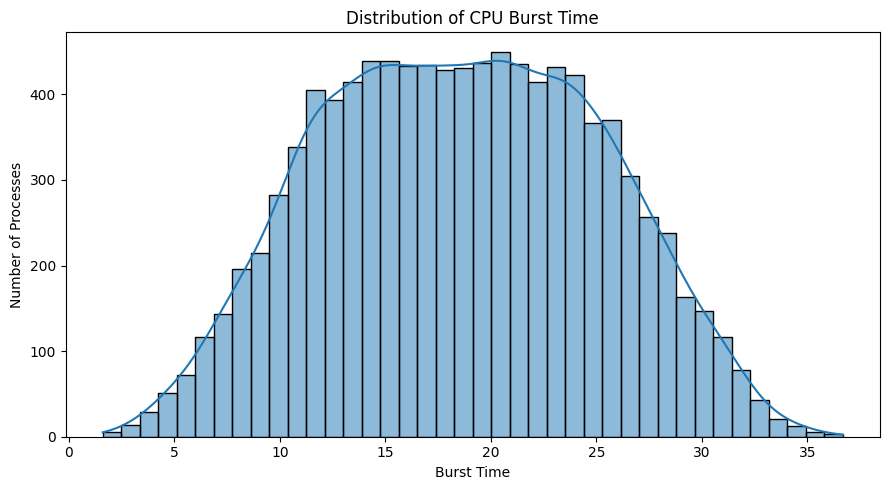

In [3]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="burst_time", bins=40, kde=True)

plt.title("Distribution of CPU Burst Time")
plt.xlabel("Burst Time")
plt.ylabel("Number of Processes")

plt.tight_layout()
plt.show()

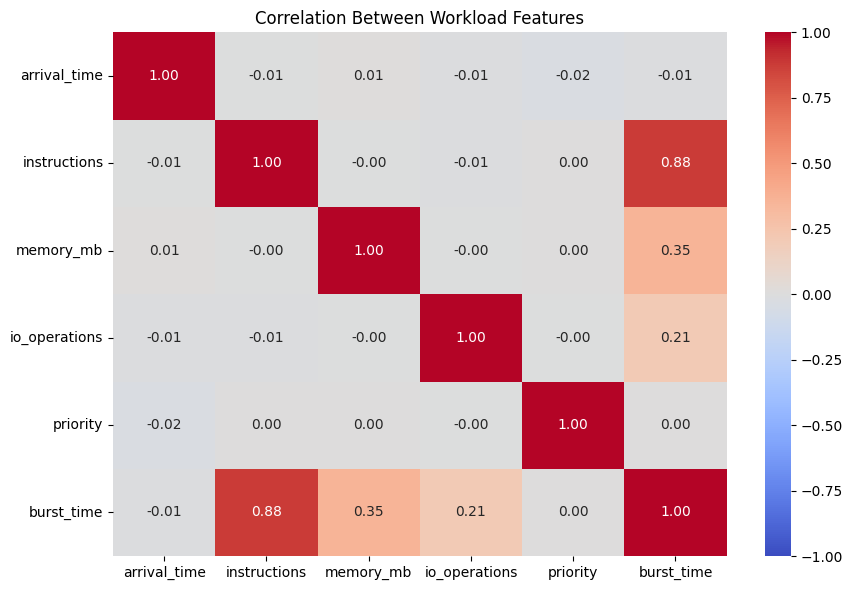

In [4]:
plt.figure(figsize=(9, 6))

correlation = df[
    [
        "arrival_time",
        "instructions",
        "memory_mb",
        "io_operations",
        "priority",
        "burst_time"
    ]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Workload Features")
plt.tight_layout()
plt.show()

,Model,MAE,RMSE,R2
0,Linear Regression,1.1831,1.4953,0.9472
1,Random Forest,1.2669,1.6036,0.9393


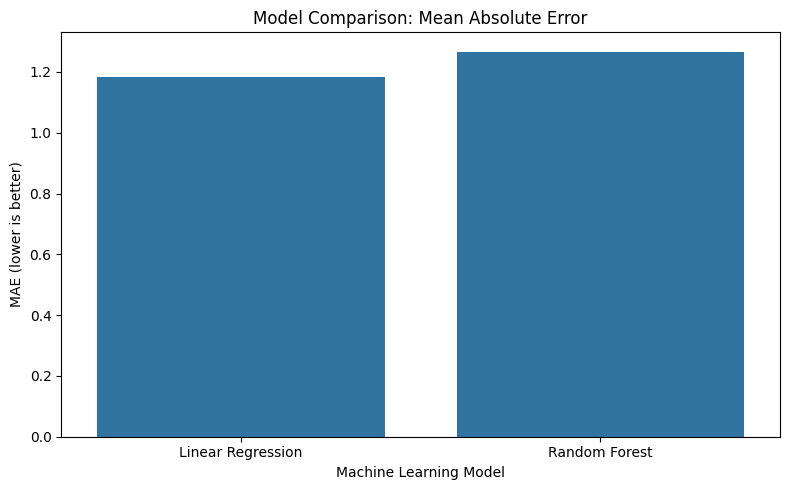

In [5]:
metrics = pd.read_csv("outputs/model_metrics.csv")

display(metrics.round(4))

plt.figure(figsize=(8, 5))

sns.barplot(data=metrics, x="Model", y="MAE")

plt.title("Model Comparison: Mean Absolute Error")
plt.ylabel("MAE (lower is better)")
plt.xlabel("Machine Learning Model")

plt.tight_layout()
plt.show()

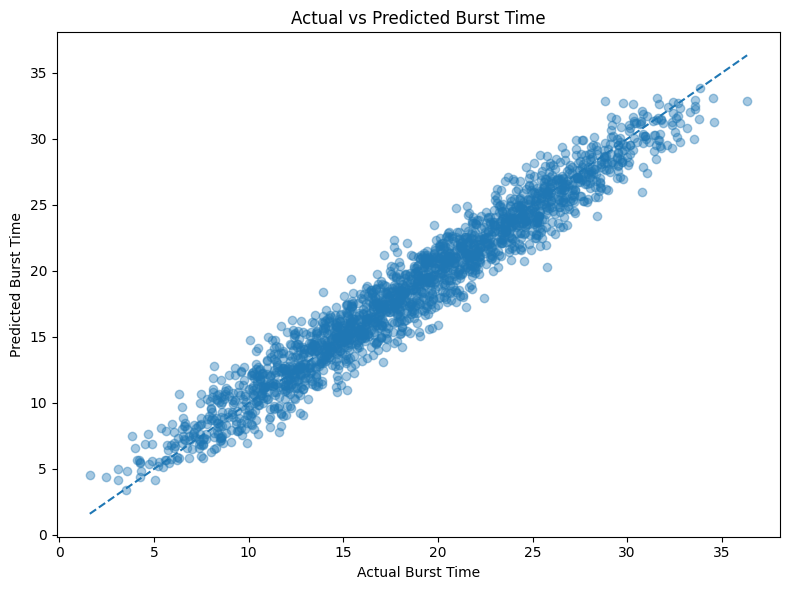

Test MAE: 1.1831


In [6]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

features = [
    "instructions",
    "memory_mb",
    "io_operations",
    "priority"
]

X = df[features]
y = df["burst_time"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = joblib.load("models/best_model.pkl")
predictions = model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.4)

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Burst Time")
plt.ylabel("Predicted Burst Time")
plt.title("Actual vs Predicted Burst Time")
plt.tight_layout()
plt.show()

print("Test MAE:", round(mean_absolute_error(y_test, predictions), 4))

,algorithm,Average_Waiting_Time,Average_Turnaround_Time
0,FCFS,927.48,946.48
1,Priority,925.92,944.92
2,Round Robin,1479.61,1498.61
3,SJF,750.30,769.29


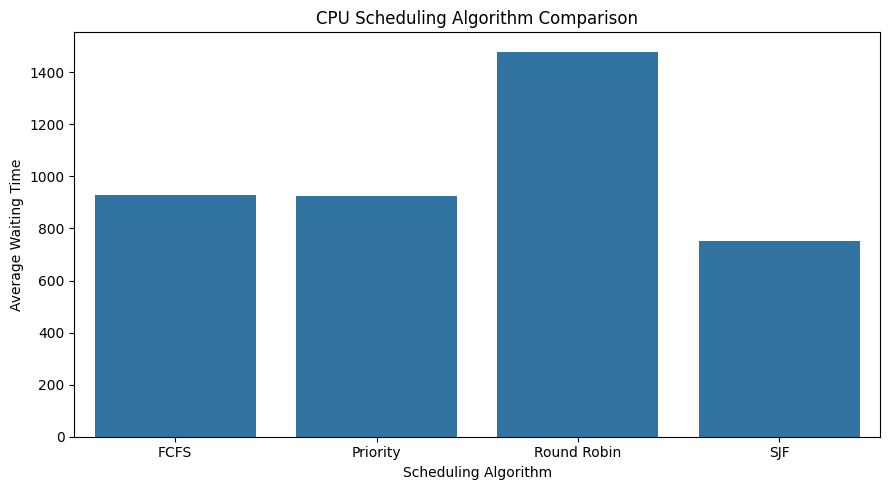

In [7]:
results = pd.read_csv("outputs/scheduling_results.csv")

summary = results.groupby("algorithm").agg(
    Average_Waiting_Time=("waiting_time", "mean"),
    Average_Turnaround_Time=("turnaround_time", "mean")
).reset_index()

display(summary.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=summary,
    x="algorithm",
    y="Average_Waiting_Time"
)

plt.title("CPU Scheduling Algorithm Comparison")
plt.xlabel("Scheduling Algorithm")
plt.ylabel("Average Waiting Time")
plt.tight_layout()
plt.show()